### **Business Problem**

**Goal here is to see if we can harness the power of machine learning and boosting to help create not just a predictive model, but a general guidline for features people should look out for when picking mushrooms.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('mushrooms.csv')
data.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [18]:
def pie(val):
    print(val)
    lst = list(data[val].value_counts())
    lbs=list(data[val].unique())
    plt.pie(lst,labels = lbs, radius = 1.5, autopct = "%1.1f%%")
    plt.show()


def count(val):
    print(val)
    sns.countplot(data=data, x= val)
    plt.show()

In [19]:
data.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [20]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124 non-null   str  
 15

In [21]:
disc = data.columns

In [22]:

for val in disc:
    counts=data[val].value_counts()
    print(val,'=',counts)
    print('*'*50)

class = class
e    4208
p    3916
Name: count, dtype: int64
**************************************************
cap-shape = cap-shape
x    3656
f    3152
k     828
b     452
s      32
c       4
Name: count, dtype: int64
**************************************************
cap-surface = cap-surface
y    3244
s    2556
f    2320
g       4
Name: count, dtype: int64
**************************************************
cap-color = cap-color
n    2284
g    1840
e    1500
y    1072
w    1040
b     168
p     144
c      44
u      16
r      16
Name: count, dtype: int64
**************************************************
bruises = bruises
f    4748
t    3376
Name: count, dtype: int64
**************************************************
odor = odor
n    3528
f    2160
y     576
s     576
a     400
l     400
p     256
c     192
m      36
Name: count, dtype: int64
**************************************************
gill-attachment = gill-attachment
f    7914
a     210
Name: count, dtype: int64
**************

class


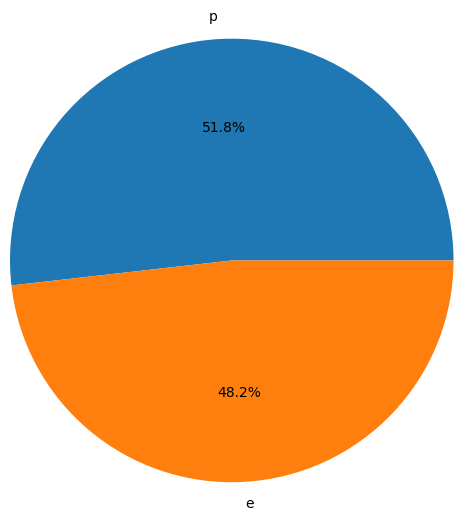

cap-shape


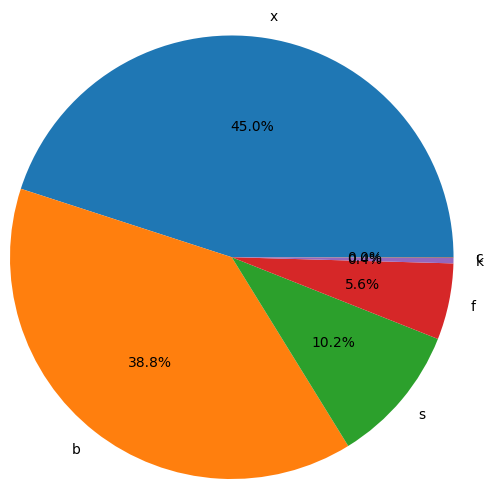

cap-surface


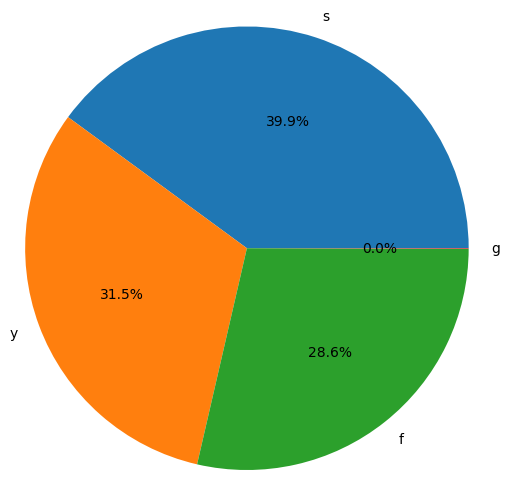

cap-color


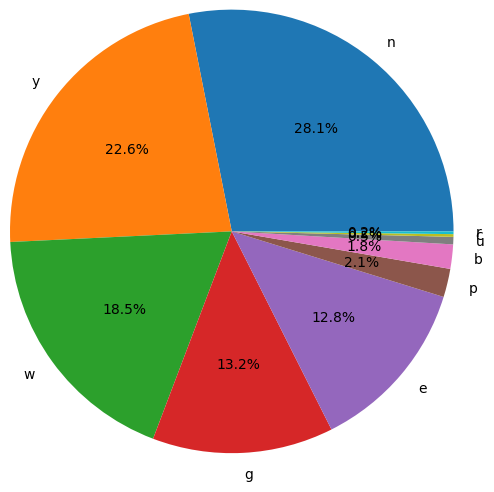

bruises


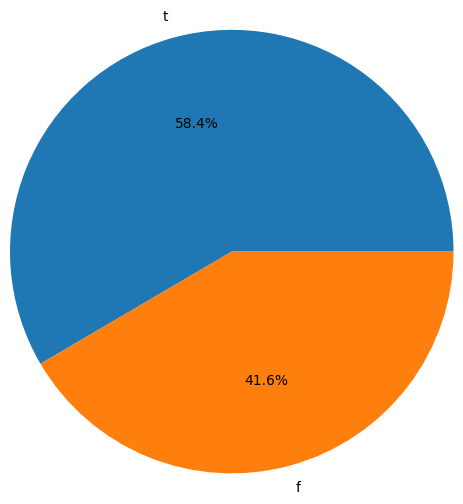

odor


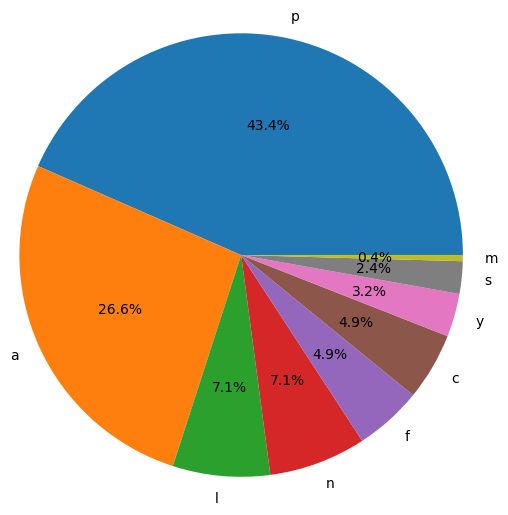

gill-attachment


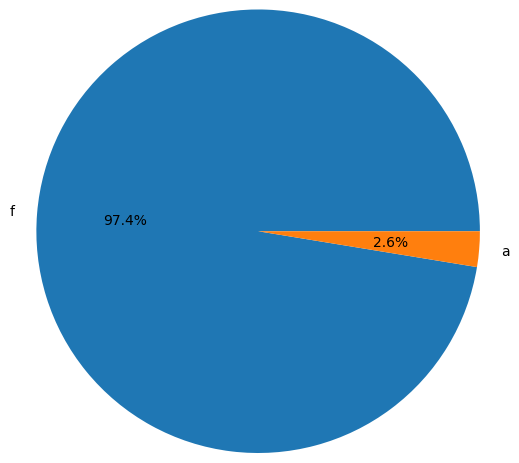

gill-spacing


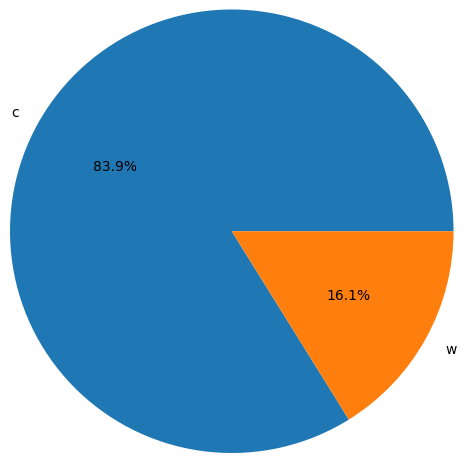

gill-size


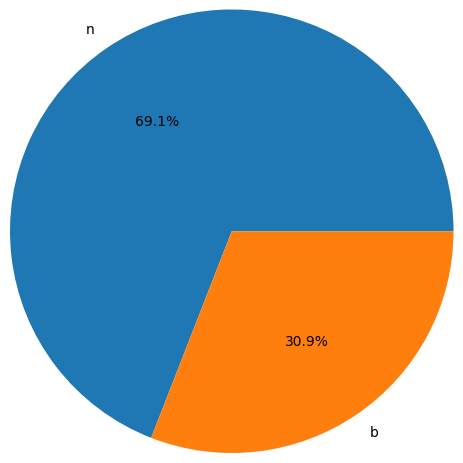

gill-color


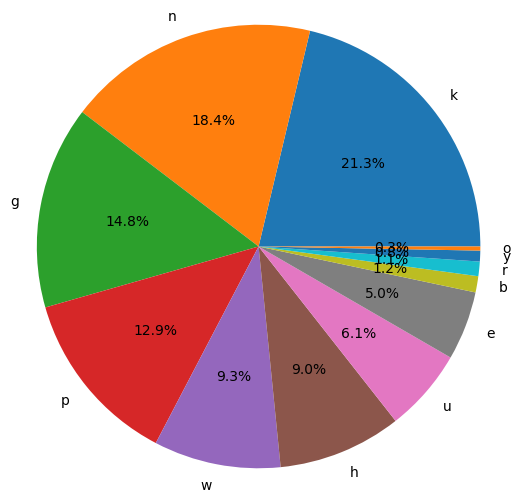

stalk-shape


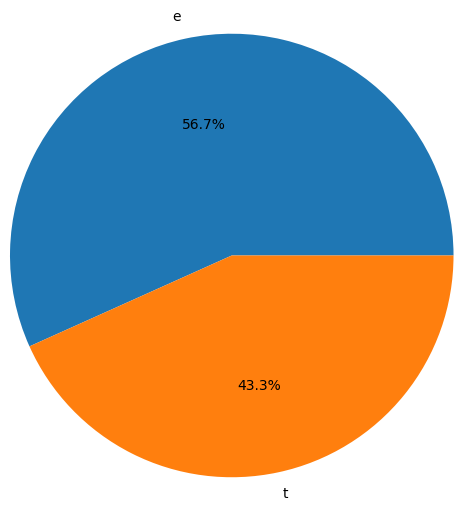

stalk-root


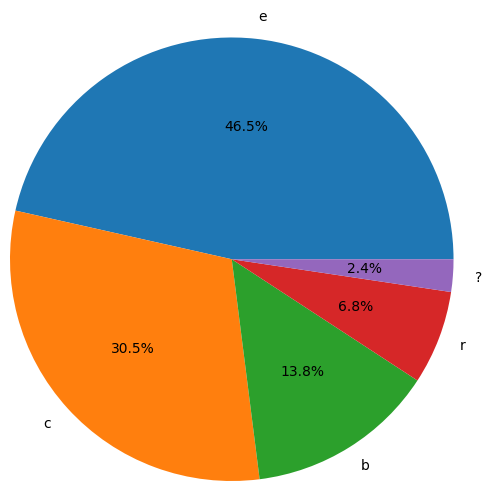

stalk-surface-above-ring


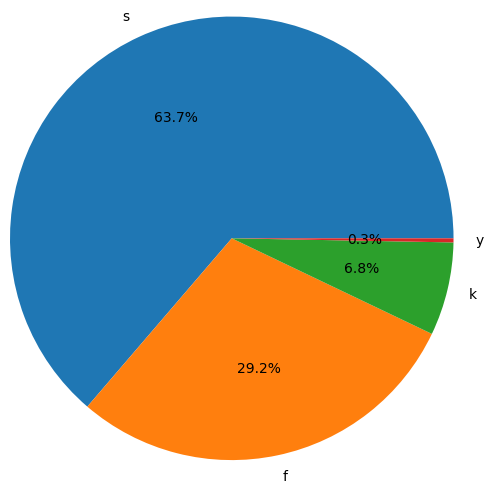

stalk-surface-below-ring


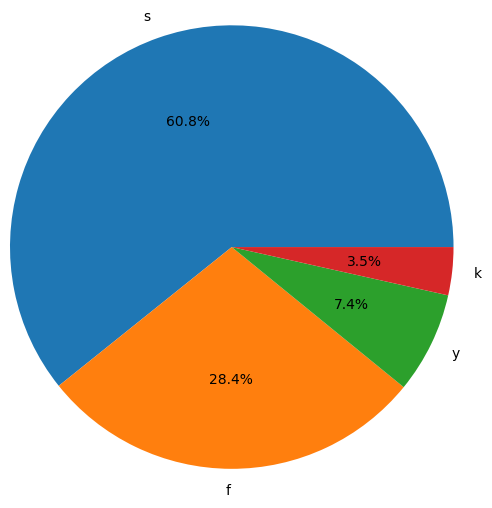

stalk-color-above-ring


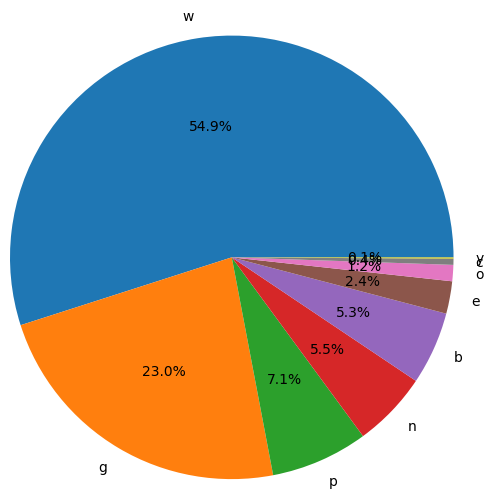

stalk-color-below-ring


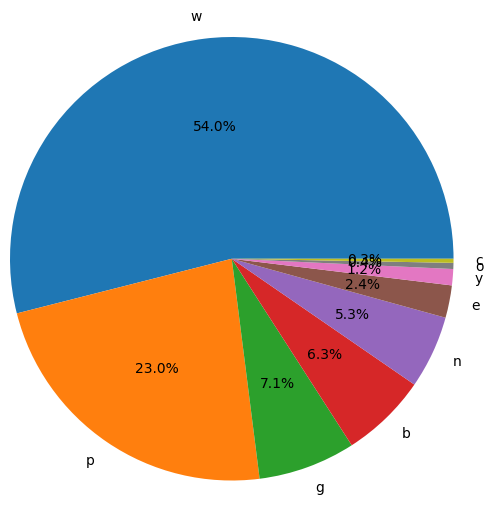

veil-type


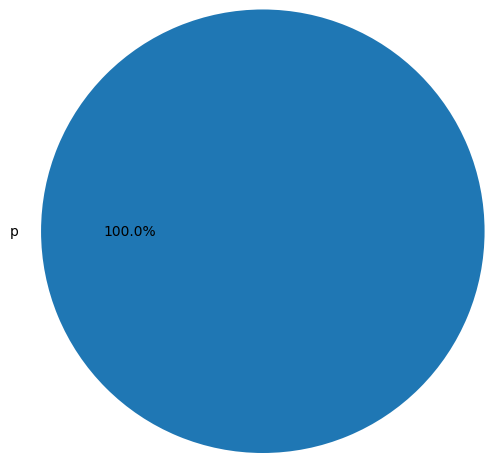

veil-color


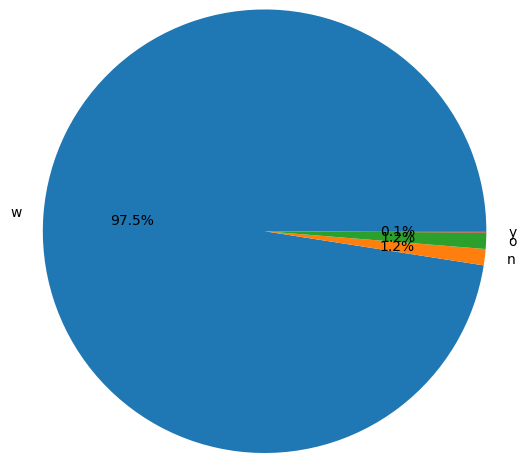

ring-number


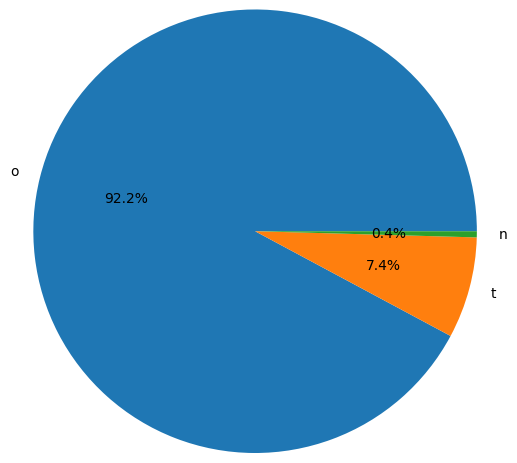

ring-type


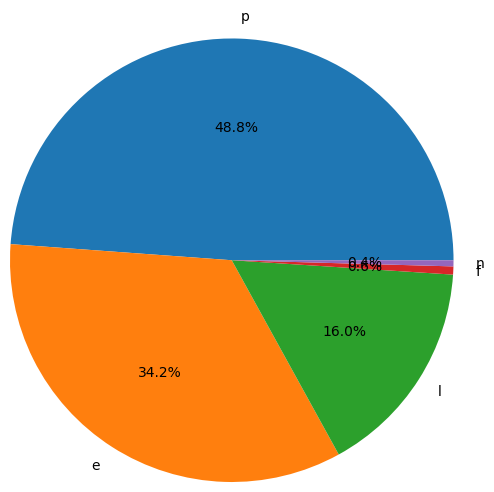

spore-print-color


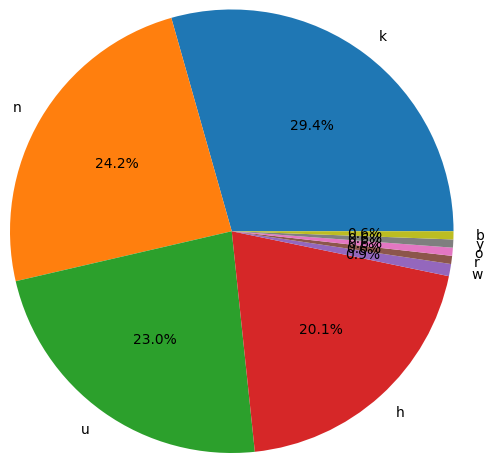

population


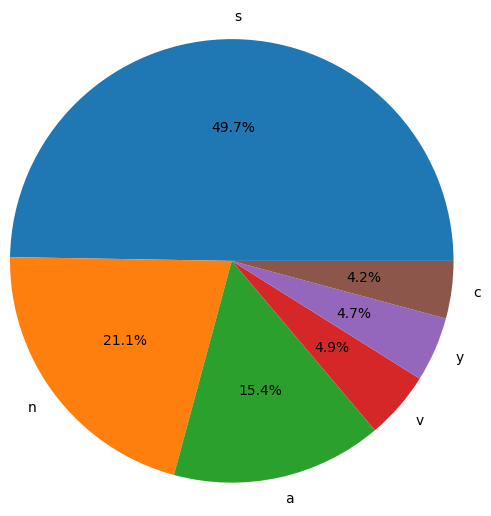

habitat


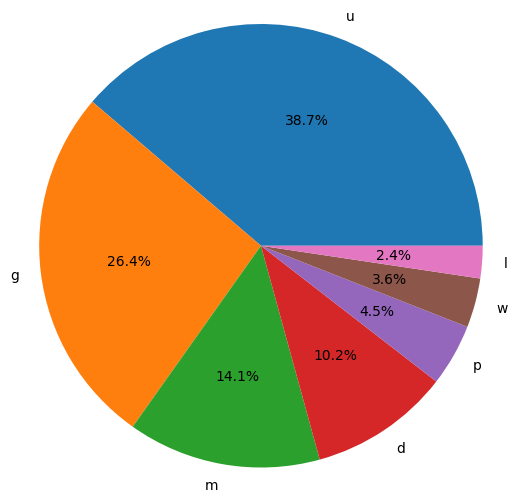

In [23]:
for val in disc:
    pie(val)

class


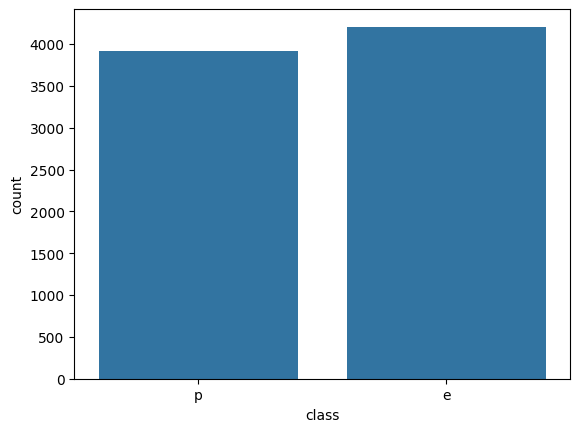

cap-shape


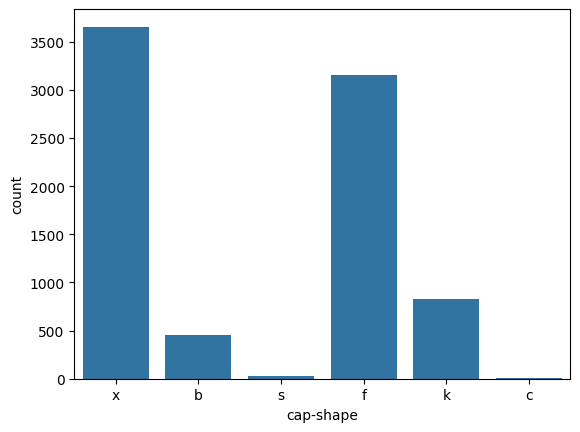

cap-surface


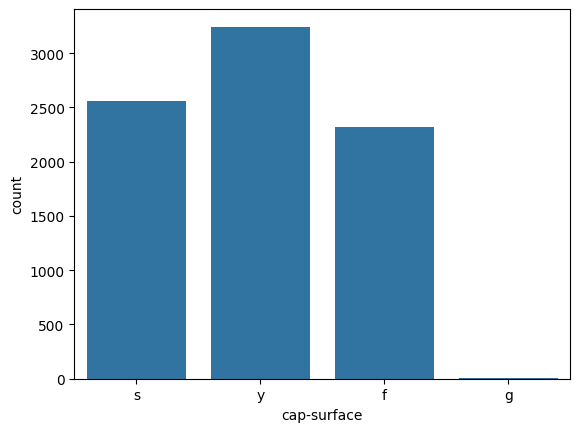

cap-color


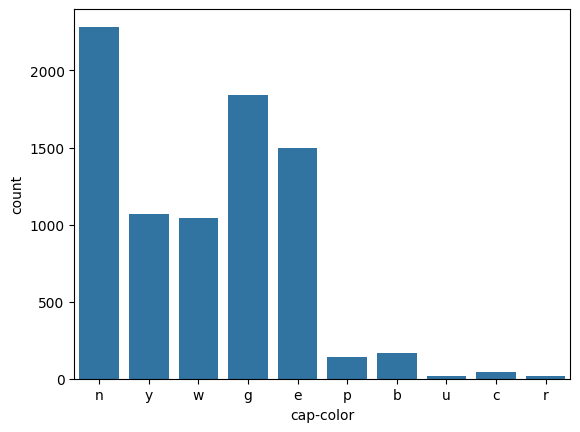

bruises


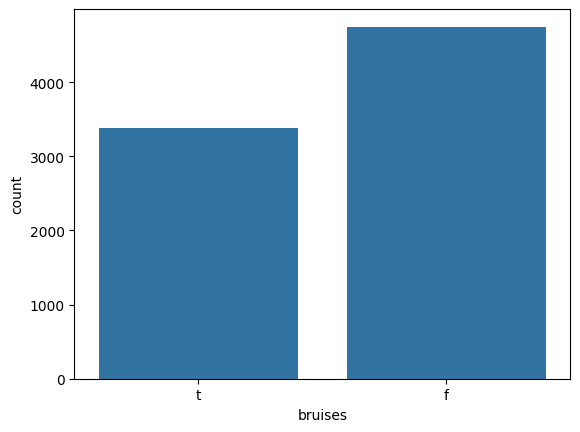

odor


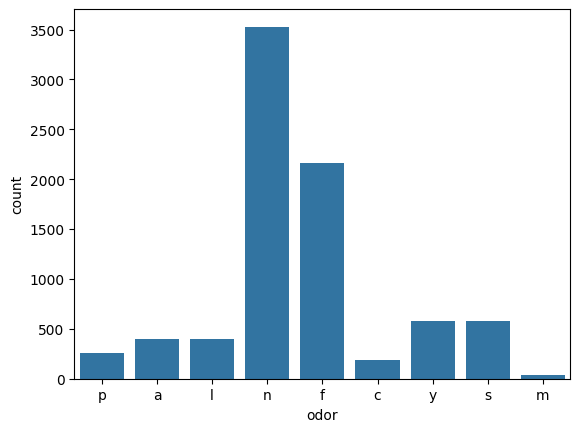

gill-attachment


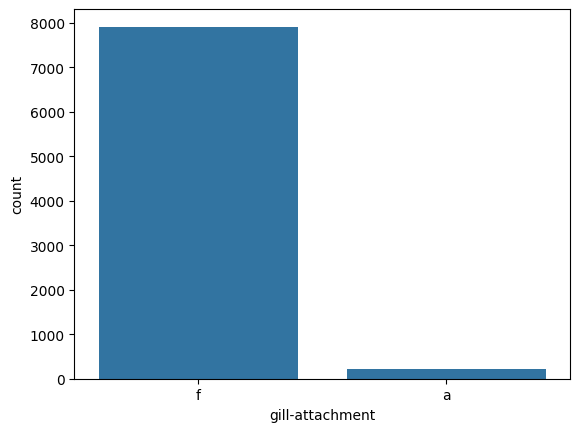

gill-spacing


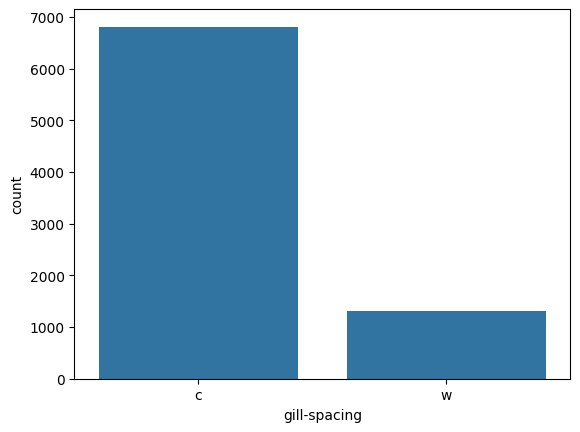

gill-size


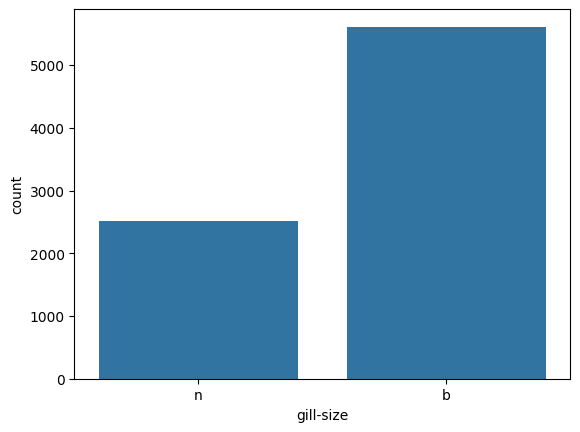

gill-color


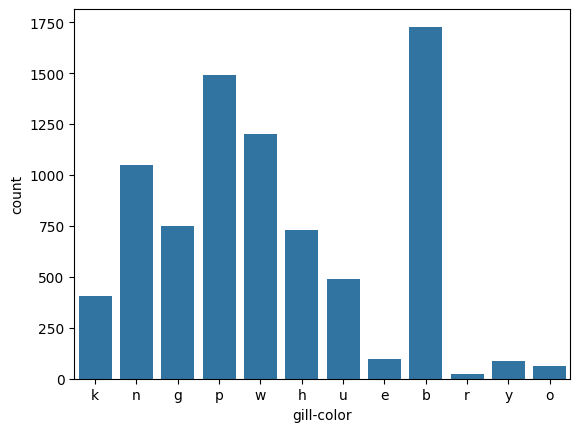

stalk-shape


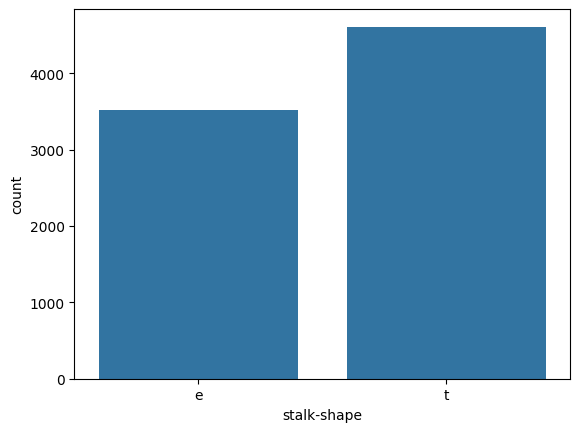

stalk-root


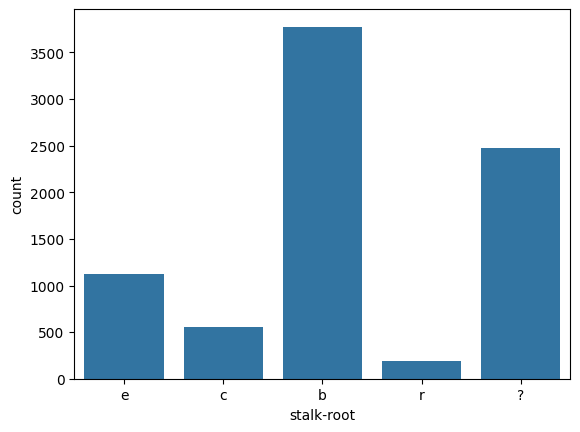

stalk-surface-above-ring


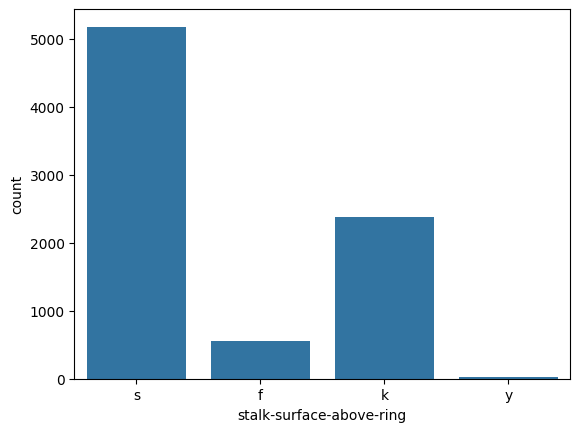

stalk-surface-below-ring


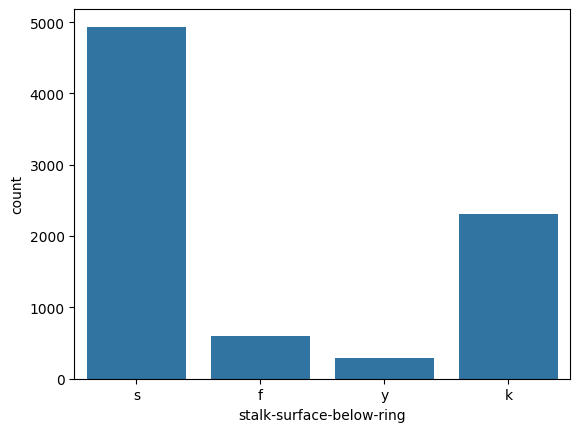

stalk-color-above-ring


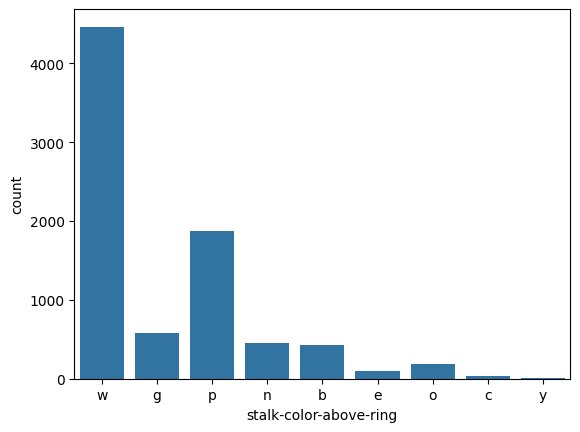

stalk-color-below-ring


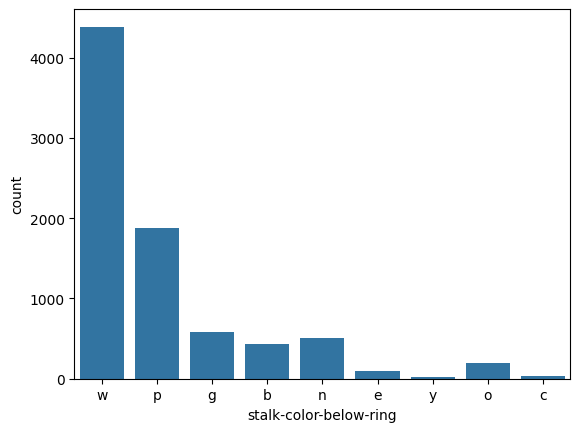

veil-type


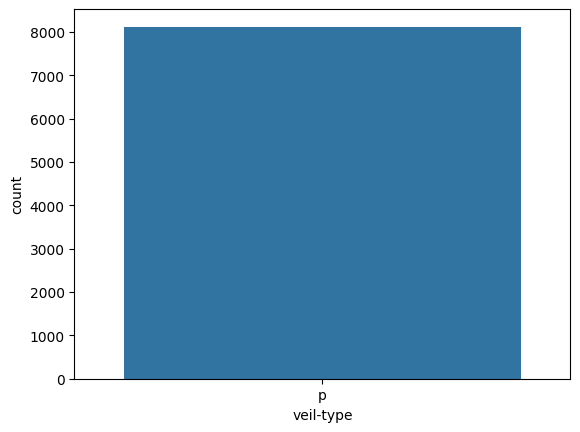

veil-color


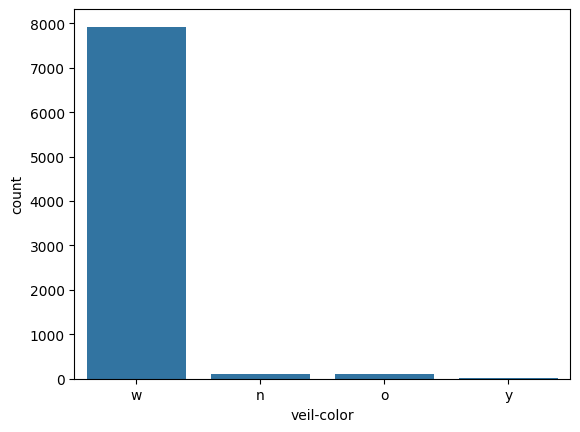

ring-number


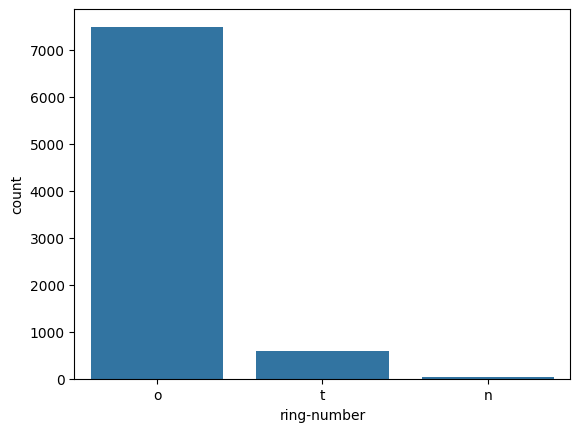

ring-type


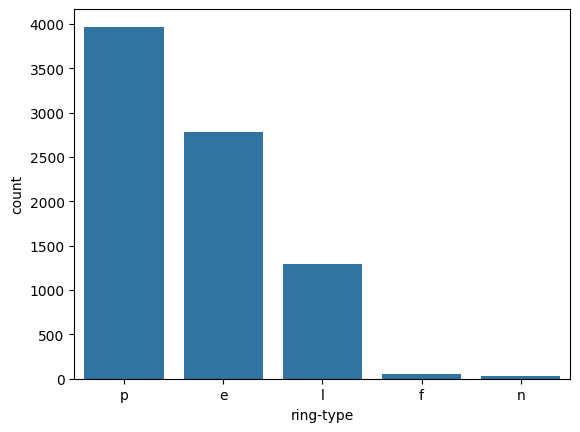

spore-print-color


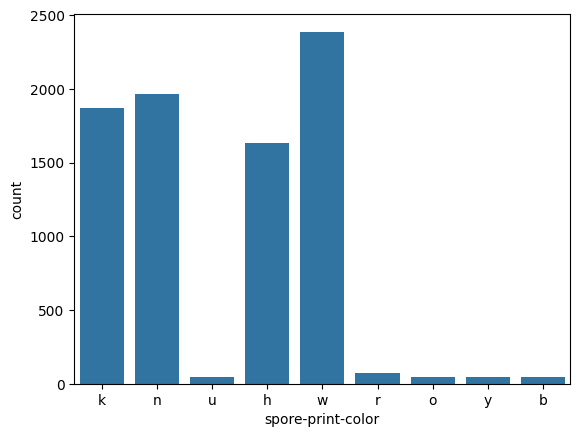

population


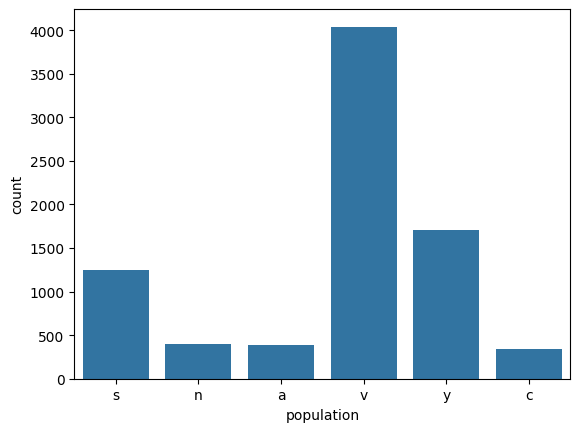

habitat


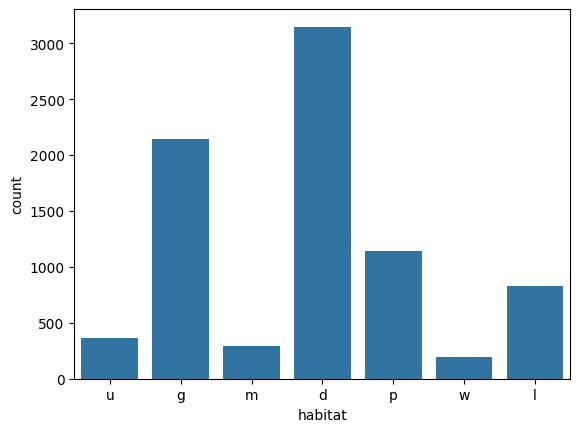

In [24]:
for val in disc:
    count(val)

In [25]:
data.describe(include='all').transpose()

,count,unique,top,freq
class,8124,2,e,4208
cap-shape,8124,6,x,3656
cap-surface,8124,4,y,3244
cap-color,8124,10,n,2284
bruises,8124,2,f,4748
odor,8124,9,n,3528
gill-attachment,8124,2,f,7914
gill-spacing,8124,2,c,6812
gill-size,8124,2,b,5612
gill-color,8124,12,b,1728


In [26]:
X = pd.get_dummies(data.drop('class', axis = 1), drop_first=True)
y = data['class']

In [27]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=101, test_size=0.15)

In [28]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import classification_report , accuracy_score
from sklearn.model_selection import cross_val_score

model = AdaBoostClassifier(random_state=101)
model.fit(X_train, y_train)

pred_train = model.predict(X_train)
pred_test = model.predict(X_test)

print(accuracy_score(y_train, pred_train))
print(accuracy_score(y_test, pred_test))


print('*'*10)

score = cross_val_score(model, X, y, cv = 5)
print('cross val score', score)
print('cross val score mean', score.mean())


print('*'*10)

print(classification_report(y_test, pred_test))

0.9866763215061549
0.9835931091058244
**********
cross val score [0.90461538 0.99446154 0.95630769 1.         0.67118227]
cross val score mean 0.9053133762788935
**********
              precision    recall  f1-score   support

           e       0.99      0.98      0.98       655
           p       0.97      0.99      0.98       564

    accuracy                           0.98      1219
   macro avg       0.98      0.98      0.98      1219
weighted avg       0.98      0.98      0.98      1219



## **Hyper Parameter Tunning**

In [29]:
from sklearn.model_selection import GridSearchCV

estimator = AdaBoostClassifier()
param_grid = {'n_estimators':list(range(1,10))}

full_cv_classifier = GridSearchCV(estimator, param_grid, cv = 5, scoring='accuracy')
print(full_cv_classifier.fit(X_train, y_train))
print(full_cv_classifier.best_params_)

GridSearchCV(cv=5, estimator=AdaBoostClassifier(),
             param_grid={'n_estimators': [1, 2, 3, 4, 5, 6, 7, 8, 9]},
             scoring='accuracy')
{'n_estimators': 8}


## **Rebuild Model**

In [34]:
model = AdaBoostClassifier(random_state=101, n_estimators=20)
model.fit(X_train, y_train)


#prediction
pred_train=model.predict(X_train)
pred_test=model.predict(X_test)
print(accuracy_score(y_train,pred_train))
print(accuracy_score(y_test,pred_test))


print('*'*10)
#cross_val_score
score= cross_val_score(model,X,y,cv=5)
print('cross_val_score =',score)
print('cross_val_score mean =',score.mean())




print('*'*50)
#cLAssification Report
print(classification_report(y_test,pred_test))

0.9756698044895004
0.9671862182116489
**********
cross_val_score = [0.82830769 0.98215385 0.95630769 1.         0.85283251]
cross_val_score mean = 0.9239203486169003
**************************************************
              precision    recall  f1-score   support

           e       0.97      0.97      0.97       655
           p       0.97      0.96      0.96       564

    accuracy                           0.97      1219
   macro avg       0.97      0.97      0.97      1219
weighted avg       0.97      0.97      0.97      1219



In [35]:
model.feature_importances_

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.16150789,
       0.0921998 , 0.        , 0.17808882, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.05574793, 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.06322904, 0.        , 0.05483035, 0.        , 0.        ,
       0.03343693, 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

In [37]:
feats = pd.DataFrame(index=X.columns,
                     data = model.feature_importances_,
                     columns=['Importance'])

feats

,Importance
cap-shape_c,0.0
cap-shape_f,0.0
cap-shape_k,0.0
cap-shape_s,0.0
cap-shape_x,0.0
...,...
habitat_l,0.0
habitat_m,0.0
habitat_p,0.0
habitat_u,0.0


In [39]:
imp_feats = feats[feats['Importance']>0]
imp_feats.sort_values('Importance')

,Importance
stalk-surface-above-ring_k,0.033437
stalk-root_c,0.054830
gill-size_n,0.055748
stalk-shape_t,0.063229
population_v,0.083485
odor_l,0.092200
ring-type_p,0.102172
odor_f,0.161508
spore-print-color_r,0.175302
odor_n,0.178089


In [40]:

imp_feats

,Importance
odor_f,0.161508
odor_l,0.092200
odor_n,0.178089
gill-size_n,0.055748
stalk-shape_t,0.063229
stalk-root_c,0.054830
stalk-surface-above-ring_k,0.033437
ring-type_p,0.102172
spore-print-color_r,0.175302
population_v,0.083485


In [74]:
lst = [
    'odor_f,'
'odor_l',
'odor_n',	
'gill-size_n',
'stalk-shape_t',	
'stalk-root_c',
'stalk-surface-above-ring_k',	
'ring-type_p',
'spore-print-color_r',	
'population_v'
]

In [75]:
data2 = data.copy()

In [76]:
data2.tail()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
8119,e,k,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,b,c,l
8120,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,n,o,p,b,v,l
8121,e,f,s,n,f,n,a,c,b,n,...,s,o,o,p,o,o,p,b,c,l
8122,p,k,y,n,f,y,f,c,n,b,...,k,w,w,p,w,o,e,w,v,l
8123,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,o,c,l


In [77]:

cols_to_drop = feats.index[feats['Importance'] > 0]

X = pd.get_dummies(
    data2.drop(columns=cols_to_drop, errors='ignore'),
    drop_first=True
)


In [78]:
print(feats.head())
print(data2.columns.tolist())

             Importance
cap-shape_c         0.0
cap-shape_f         0.0
cap-shape_k         0.0
cap-shape_s         0.0
cap-shape_x         0.0
['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']
